# Phase 5: Do real fire seasons follow El Niño?

The model says drought pushes forests past a critical point, so fire activity should jump in dry years. Here we test that against real data:

* **Fire activity:** NASA FIRMS MODIS active-fire detections, 2001–2025, Indonesia and Australia. A detection is a 1 km pixel seen burning by the Terra or Aqua satellite. Counts are a proxy for fire activity, not burned area.
* **El Niño:** NOAA's Niño 3.4 index, the sea-surface temperature anomaly in the central Pacific. Above +0.5 °C is El Niño, below −0.5 °C La Niña.

Run `scripts/download_real_data.py` once (about 600 MB, 4 minutes); this notebook reads only the small monthly tables it writes.

In [1]:
# Setup: works locally (run from notebooks/) and in Google Colab.
# In Colab the code is cloned from GitHub if that repo exists; otherwise copy the project folder
# to Google Drive as MyDrive/forest_fire.
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.isdir("src/forest_fire"):
    repo = "https://github.com/nhamhhung/forest-fire-spread.git"
    if subprocess.run(["git", "clone", "-q", repo, "/content/forest_fire"]).returncode == 0:
        os.chdir("/content/forest_fire")
    else:
        from google.colab import drive
        drive.mount("/content/drive")
        os.chdir("/content/drive/MyDrive/forest_fire")
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "numba"], check=True)
root = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(root, "src"))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from forest_fire import real_data as rd
fires = pd.read_csv(rd.PROCESSED / "firms_monthly.csv")
nino = pd.read_csv(rd.PROCESSED / "nino34_monthly.csv")
fires.head()

,year,month,detections,country
0,2001,1,51,Indonesia
1,2001,2,239,Indonesia
2,2001,3,683,Indonesia
3,2001,4,134,Indonesia
4,2001,5,368,Indonesia


## 1. Indonesia, month by month

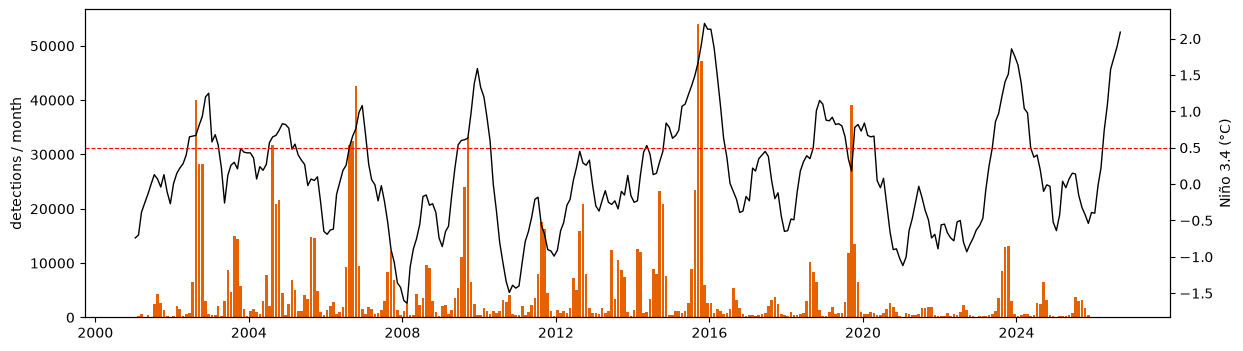

In [2]:
indo = fires[fires.country == "Indonesia"]
t = pd.to_datetime(dict(year=indo.year, month=indo.month, day=15))
n = nino[(nino.year >= 2001)]; tn = pd.to_datetime(dict(year=n.year, month=n.month, day=15))
fig, ax = plt.subplots(figsize=(14, 4)); ax.bar(t, indo.detections, width=25, color="#e66101"); ax.set_ylabel("detections / month")
ax2 = ax.twinx(); ax2.plot(tn, n.nino34, "k", lw=1); ax2.axhline(0.5, color="r", ls="--", lw=.8); ax2.set_ylabel("Niño 3.4 (°C)")
plt.show()

## 2. Fire season vs El Niño, year by year

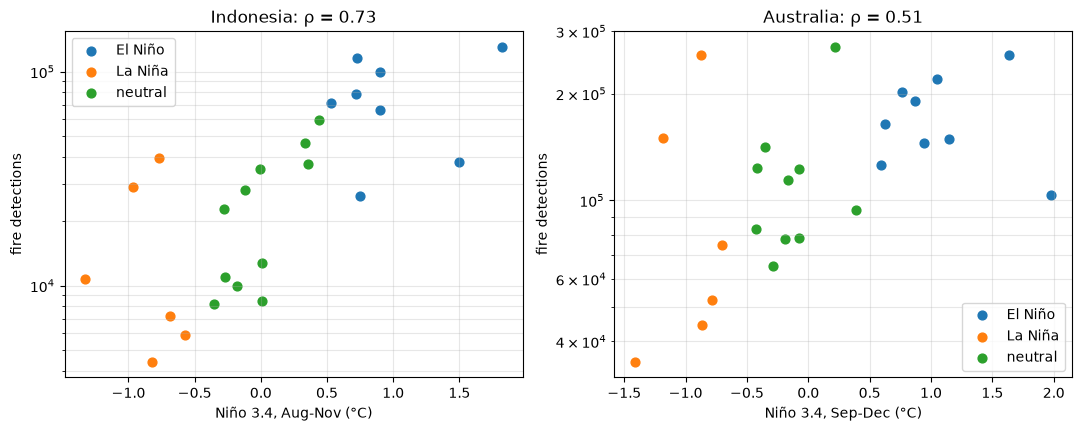

years    median      mean  mean_vs_neutral  permutation_p
          phase                                                             
Indonesia La Niña      6    8987.0   16080.0              0.6         0.0002
          neutral     11   22749.0   25382.9              1.0         0.0002
          El Niño      8   74971.5   78343.1              3.1         0.0002
Australia La Niña      6   63537.0  102158.8              0.9         0.0052
          neutral     10  104204.5  117142.1              1.0         0.0052
          El Niño      9  164617.0  172982.1              1.5         0.0052

In [3]:
out = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, c in zip(axes, rd.SEASONS):
    tab = rd.seasonal_table(fires, nino, c)
    for phase, d in tab.groupby("phase"):
        ax.scatter(d.nino34, d.detections, label=phase, s=40)
    rho = spearmanr(tab.nino34, tab.detections).statistic
    ax.set(yscale="log", xlabel=f"Niño 3.4, {rd.SEASONS[c]['label']} (°C)", ylabel="fire detections", title=f"{c}: ρ = {rho:.2f}")
    ax.legend(); ax.grid(alpha=.3, which="both")
    out[c] = rd.phase_comparison(tab).round(1).assign(permutation_p=rd.permutation_test(tab))
plt.show()
pd.concat(out)

## What the data says

* **Indonesia (Aug–Nov):** El Niño fire seasons average about **3× more fire detections** than neutral ones, and La Niña seasons about 0.6×. The six largest fire seasons since 2001 were all El Niño years, led by 2015. The rank correlation with Niño 3.4 is 0.73, and a permutation test puts the chance of a gap this large under no link at about 1 in 5,000.
* **Australia (Sep–Dec):** the link is real but weaker: about 1.5× more detections in El Niño seasons, ρ ≈ 0.5. The largest seasons include a neutral year (2012) and a La Niña year (2011). Wet years can grow extra grass fuel in the northern savannas, a fuel effect this model does not have.
* **Fire counts rise roughly exponentially with Niño 3.4** (a straight line on the log scale). This matches the model's message that drying fuel does not add fire linearly: it pushes landscapes across a threshold.
* **Not everything fits.** 2023 was a strong El Niño, yet Indonesia's fire season was moderate. Peatland restoration and fire-prevention policy after 2015 may play a part, but this analysis cannot separate that from other causes.

## The 2026–27 El Niño
NOAA's Niño 3.4 anomaly reached **+2.09 °C in September 2026**, above the 2015 peak season mean (1.82 °C for Aug–Nov). FIRMS has not yet published 2026 in its yearly archive, so the 2026 fire season cannot be scored here. Historically, seasons this warm have been Indonesia's worst, so the model and the record agree that the risk is high. That is an analogy, not a forecast.